# 02 – Envelope: minimal average enclosing volume (electron)

## 1. Introduction

This model does not describe the average density but an **envelope**: the smallest body of revolution that contains most of the showers.
Think of it as the **smallest bag** that holds 95% of the energy for 98% of electron showers of a given energy.
Going to 100% is not worthwhile: a few strongly fluctuating showers would make the bag needlessly large, which would later hurt
the separation of nearby showers.

Envelope shape:

$$r(z') = A\, u^{a} e^{-b u}, \qquad u = z' - z_0, \qquad V = \pi A^2\, \frac{\Gamma(2a+1)}{(2b)^{2a+1}}$$

- $a$, $b$: the envelope shape; the thickest point is at depth $z' = z_0 + a/b$ (in the table `z_env` $= a/b$ measured from $z_0$, `z_thick` $= z_0 + a/b$).
- $A$: the size.
- $z_0$: the starting point (the origin is the first layer; due to oblique incidence negative $z'$ also occurs).
- $V$: the envelope **volume**, i.e. the volume of the body of revolution obtained by rotating the curve $r(z')$ around the $z'$ axis.
  At each depth $z'$ the envelope cross-section is a circle of area $\pi r(z')^2$; these are summed along the depth:

$$V = \int_{z_0}^{\infty} \pi\, r(z')^2 \, dz' = \pi A^2 \int_0^{\infty} u^{2a} e^{-2bu}\, du = \pi A^2\, \frac{\Gamma(2a+1)}{(2b)^{2a+1}}$$

  The last step is the definition of the Gamma function ($\int_0^\infty u^{k} e^{-cu} du = \Gamma(k+1)/c^{k+1}$). $V$ comes out in mm³; in plots
  and tables it is shown in litres ($1\ \mathrm{L} = 10^6\ \mathrm{mm}^3$, column `V_L`).
  Reason for the conversion: $1\ \mathrm{L} = 1\ \mathrm{dm}^3 = (100\ \mathrm{mm})^3 = 10^6\ \mathrm{mm}^3$; in the code `V_L = exp(log_volume) / 1e6`.
  This is **for display only**: in mm³ the volumes are of order $10^7$ (e.g. 45 L = 45 000 000 mm³), which is hard to read in tables and
  on plot axes, while litres give manageable numbers. **It does not affect the fit:** the optimisation
  minimises $\ln V$ in mm³, and a constant factor inside the logarithm is just an added constant, so the location of the minimum is the same.

  **What is $V$ for?** It is the **objective function** of the fit: among envelopes satisfying the condition we seek the one with the smallest $V$. In a single number
  it measures how much space a shower "occupies" in the detector. The smaller it is, the closer two showers can be while still
  being separable. The integral runs to $z' \to \infty$, but the envelope thins quickly due to the $e^{-bu}$ term, so the part beyond the detector
  is negligible.

**Recipe:** in every 1 GeV momentum bin we find the smallest $V$ that satisfies the condition, then look at how
$A$, $a$, $b$ change with energy.

**A simplifying trick:** for a fixed shape ($a, b, z_0$) the smallest valid $A$ can be computed **exactly**. For each deposit we compute
what $A$ would be needed for it to be inside. For a shower we need the energy-weighted 95% quantile of these, and $A$ is the 98th percentile of those
across showers. So only three parameters need to be searched.

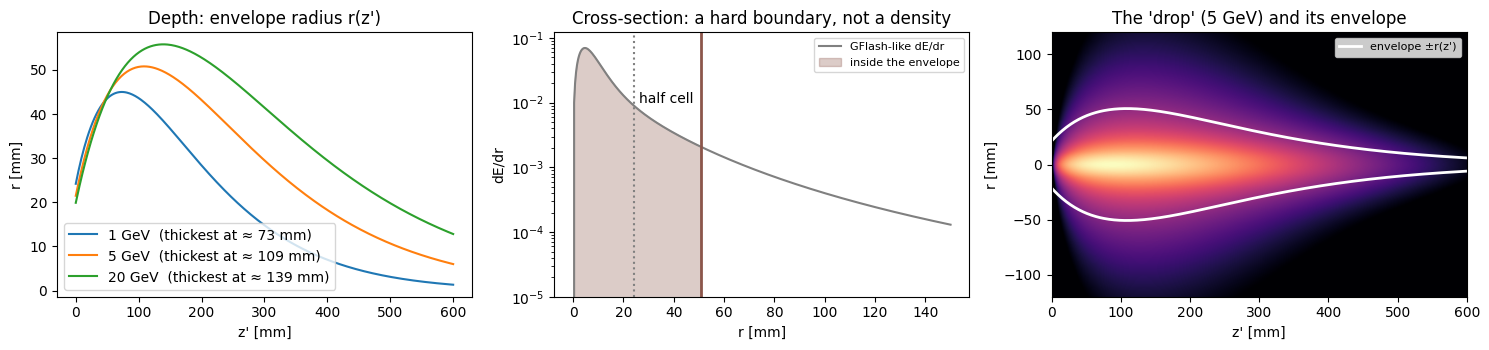

In [1]:
import numpy as np, matplotlib.pyplot as plt

# the same illustrative shower as in the GFlash notebook (01), so the two introductions can be compared panel by panel
X0, EC = 22.0, 0.0217                       # illustrative: radiation length [mm], critical energy [GeV]
Rc, Rt, pc, z0 = 8.0, 35.0, 0.85, -25.0
z = np.linspace(0.1, 600, 400)


def envelope(z, E):
    """Illustrative envelope: thickest point follows t_max (grows with ln E), the radius is nearly energy independent."""
    zenv = X0 * (np.log(E / EC) - 0.5)
    a = 1.0; b = a / (zenv - z0); rmax = 45 * (1 + 0.08 * np.log(E))
    u = np.clip(z - z0, 0, None)
    return rmax * (u / (zenv - z0)) ** a * np.exp(-b * u + a), zenv


fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for E in (1, 5, 20):
    r, zenv = envelope(z, E)
    ax[0].plot(z, r, label=f"{E} GeV  (thickest at ≈ {zenv:.0f} mm)")
ax[0].set(title="Depth: envelope radius r(z')", xlabel="z' [mm]", ylabel="r [mm]"); ax[0].legend()

rr = np.linspace(0, 150, 400)
T = (pc * Rc**2 / (rr**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (rr**2 + Rt**2)**2) / np.pi
dEdr = 2 * np.pi * rr * T
r_env = envelope(np.array([X0 * (np.log(5 / EC) - 0.5)]), 5)[0][0]
ax[1].semilogy(rr, dEdr, c="grey", label="GFlash-like dE/dr")
ax[1].fill_between(rr, 1e-6, dEdr, where=rr <= r_env, color="tab:brown", alpha=0.3, label="inside the envelope")
ax[1].axvline(r_env, c="tab:brown", lw=2); ax[1].axvline(24, ls=":", c="grey"); ax[1].text(26, 1e-2, "half cell")
ax[1].set_ylim(1e-5, None)
ax[1].set(title="Cross-section: a hard boundary, not a density", xlabel="r [mm]", ylabel="dE/dr"); ax[1].legend(fontsize=8)

Z, R = np.meshgrid(z, np.linspace(-120, 120, 241))
tmax = X0 * (np.log(5 / EC) - 0.5); bb = 0.5 / X0; aa = 1 + bb * tmax
rc = Rc * (1 + Z / 250)
rho = Z ** (aa - 1) * np.exp(-bb * Z) * (pc * rc**2 / (R**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (R**2 + (4 * rc)**2)**2)
ax[2].imshow(np.log10(rho + 1e-30), extent=[0, 600, -120, 120], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(rho.max()) - 4)
r5, _ = envelope(z, 5)
ax[2].plot(z, r5, c="white", lw=2); ax[2].plot(z, -r5, c="white", lw=2, label="envelope ±r(z')")
ax[2].set_ylim(-120, 120); ax[2].legend(loc="upper right", fontsize=8)
ax[2].set(title="The 'drop' (5 GeV) and its envelope", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

**Same plots as for GFlash (01):** with the same illustrative shower, so they can be compared panel by panel.
- **Left:** GFlash describes the *depth profile* ($dE/dz'$), the envelope the *radius* ($r(z')$). Here too the thickest point moves deeper
  with energy together with the shower maximum, while the radius barely grows.
- **Middle:** GFlash gives a density ($dE/dr$, grey). The envelope instead is a **hard boundary**: whatever is inside the brown line is "in".
- **Right:** the same "drop" as for GFlash, with the envelope outline $\pm r(z')$ drawn on it.

The plot below shows the fluctuations: the envelope is sized not for the average shower but for 98% of the showers.

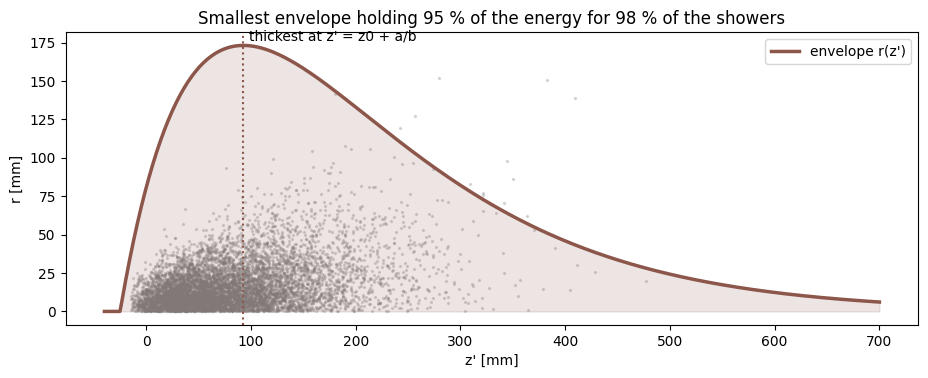

In [2]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(11, 3.8))
for k in range(25):                                         # 25 synthetic showers with fluctuating depth and width
    n = 300; s = rng.gamma(3 + rng.normal(0, 0.6), 35, n); q = np.abs(rng.normal(0, 10 + 0.12 * s * rng.uniform(0.7, 1.4)))
    ax.scatter(s - 15, q, s=2, alpha=0.25, c="grey")
A, a, b, z0 = 4.0, 1.0, 0.0085, -25
z = np.linspace(-40, 700, 400); u = np.clip(z - z0, 0, None); r = A * u ** a * np.exp(-b * u)
ax.fill_between(z, 0, r, color="tab:brown", alpha=0.15); ax.plot(z, r, c="tab:brown", lw=2.5, label="envelope r(z')")
ax.axvline(z0 + a / b, ls=":", c="tab:brown"); ax.text(z0 + a / b + 5, r.max() * 1.02, "thickest at z' = z0 + a/b")
ax.set(xlabel="z' [mm]", ylabel="r [mm]", title="Smallest envelope holding 95 % of the energy for 98 % of the showers")
ax.legend(); plt.show()

## 2. Loading data

In [3]:
PARTICLES = ['electron']
DATA_DIR = "../../data/simulations/regression-electron/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-electron/ | output: results


In [4]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

electron: 99995 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69996, val 14999, test 15000

===== electron =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11436422 entries, 0 to 11436421
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi            

,count,mean,std,min,25%,50%,75%,max
event_number,11436422.0,1.048876e+05,6.064561e+04,0.000000e+00,5.242900e+04,1.046690e+05,1.574530e+05,2.099990e+05
cellID,11436422.0,1.333742e+09,1.039108e+09,4.212000e+03,5.748668e+08,1.136943e+09,2.152149e+09,5.063301e+09
x,11436422.0,1.152600e+00,1.275030e+03,-2.596035e+03,-9.837540e+02,3.040900e+01,9.887540e+02,2.601035e+03
y,11436422.0,-4.532280e+00,1.274187e+03,-2.599800e+03,-9.838000e+02,-2.620000e+01,9.838000e+02,2.599800e+03
z,11436422.0,3.827699e+03,1.244528e+02,3.662400e+03,3.744400e+03,3.805900e+03,3.887900e+03,4.871900e+03
x_local,11436422.0,-3.327809e+00,8.815675e+01,-4.059289e+03,-4.077562e+01,-3.618190e+00,3.370563e+01,1.906138e+03
y_local,11436422.0,2.443006e-02,7.864957e+01,-2.458475e+03,-3.993694e+01,0.000000e+00,3.998249e+01,2.604588e+03
z_local,11436422.0,1.773651e+02,1.277168e+02,-2.891128e+03,8.518457e+01,1.594890e+02,2.478127e+02,1.516132e+03
x_trans,11436422.0,-4.924299e-01,1.009526e+02,-4.312513e+03,-5.151632e+01,0.000000e+00,5.133581e+01,4.081322e+03
y_trans,11436422.0,-2.044345e-01,1.005016e+02,-3.936125e+03,-5.129690e+01,0.000000e+00,5.125513e+01,4.848162e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,70485,29940084,31.983999,-882.799988,3662.399902,-50.890334,56.424332,-12.768919,57.538069,51.243998,...,0.000023,12.900945,10.534635,0.245835,-1.592273,10,gamma,1,e+,e-
1,112266,625584500,-1387.531982,-1185.800049,3887.899902,-35.797512,6.624244,232.702962,-47.734647,-48.447546,...,0.000207,14.417011,14.137709,0.444255,-2.446334,14,gamma,1,e-,e-
2,158539,1610801268,-430.761993,1488.800049,3723.899902,31.214213,36.340932,79.157411,-50.866447,46.810689,...,0.009759,13.415966,18.627253,0.387387,1.844146,18,e+,1,gamma,gamma;gamma;gamma;gamma;gamma
3,38079,562383220,1695.364990,430.200012,3682.899902,81.715416,-27.612063,59.755805,102.907916,-0.549724,...,0.000112,13.918079,7.799625,0.427491,0.266301,7,e-,1,e-,NaN
4,106394,1623446900,435.761993,1084.800049,3723.899902,-1.097030,-54.012457,64.099259,56.964273,-0.292622,...,0.000003,13.282524,19.222589,0.303365,1.242286,19,e+,1,gamma,gamma;gamma;e-;gamma;gamma;e-;gamma;gamma;gamm...


## 3. The model

Three steps:

1. **Deposits:** every hit is split into a few points within the cell (the same detector convolution as for the other models).
2. **Exact $A$:** `required_logA` computes the required $\log A$ for each shower (weighted quantile), and `bin_threshold` takes
   their 98th percentile.
3. **Search:** a coarse grid search over $(a, z_{env}=a/b, z_0)$, then Nelder–Mead refinement. The objective is $\log V$.

### What do we fit to, and what affects the estimate?

This is **not a likelihood fit** but a per-bin volume minimisation, so the data affect it differently than the density models:
- **Features used:** `x_local, y_local, z_local` → $z'$, $r$ and `energy` → $w$ (normalised per event). Every hit is split into $K=8$
  points within the rotated cell (`deposits`, which needs the `incoming_theta`, `incoming_phi` columns and the geometry).
- **Momentum:** not a continuous condition. Data are **split into 1 GeV bins** by `incoming_momentum_bin`, and each bin is fitted separately;
  the bin mean of `incoming_momentum` is only needed for the later $\ln p$ polynomial.
- **Objective:** $\log V$, subject to $F_E=95\%$ of the energy being inside the envelope for $F_{EV}=98\%$ of the showers.
  Hence the envelope is determined by **the fluctuations of individual showers** (the extreme showers), not by the average shape.
- **What else affects it:** the values of $F_E$ and $F_{EV}$, the number of training events per bin (on a small sample 98% is effectively the worst shower),
  the grid-search range and the Nelder–Mead starting point. The same cuts apply (`earliest_contribution_time`, $z'$ and $r$ range).
- There is **no** back-face truncation ($z_b$) and no validation early stopping; the test set is only used to check coverage.

In [5]:
F_E, F_EV = 0.95, 0.98                       # energy fraction inside, for this fraction of the showers


def deposits(sh, K=8, seed=3):
    """Every hit -> K points inside its (rotated) cell, weight w/K."""
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def required_logA(P, a, b, z0, f_e=F_E):
    """Per shower: smallest log A that puts a fraction f_e of its energy inside r = A u^a e^{-bu}."""
    u = P["z"] - z0
    s = torch.full_like(u, float("inf"))                                  # points before z0 can never be inside
    ok = u > 0
    s[ok] = torch.log(P["r"][ok].clamp_min(1e-6)) - a * torch.log(u[ok]) + b * u[ok]
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]                        # sorted by shower, then by s
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def bin_threshold(P, a, b, z0, f_ev=F_EV):
    return float(np.quantile(required_logA(P, a, b, z0).cpu().numpy(), f_ev, method="higher"))


def log_volume(logA, a, b):
    return math.log(math.pi) + 2 * logA + math.lgamma(2 * a + 1) - (2 * a + 1) * math.log(2 * b)


def fit_bin(P):
    def objective(x):
        a, zenv, z0 = math.exp(x[0]), math.exp(x[1]), x[2]
        if not (0.05 < a < 10 and 3 < zenv < 1000 and -200 < z0 < 50):
            return 1e6
        logA = bin_threshold(P, a, a / zenv, z0)
        return log_volume(logA, a, a / zenv) if np.isfinite(logA) else 1e6
    grid = [(la, lz, z0) for la in np.linspace(math.log(0.1), math.log(6), 12)
            for lz in np.linspace(math.log(5), math.log(600), 12) for z0 in (-60, -30, -10)]
    x0 = min(grid, key=objective)
    x = minimize(objective, x0, method="Nelder-Mead", options={"maxiter": 300}).x
    a, zenv, z0 = math.exp(x[0]), math.exp(x[1]), x[2]
    logA = bin_threshold(P, a, a / zenv, z0)
    return {"a": a, "b": a / zenv, "z_env": zenv, "z0": z0, "A": math.exp(logA),
            "r_max": math.exp(logA) * zenv ** a * math.exp(-a), "V_L": math.exp(log_volume(logA, a, a / zenv)) / 1e6}


def coverage(P, e):
    """Fraction of showers that keep >= F_E of their energy inside envelope e."""
    return float((required_logA(P, e["a"], e["b"], e["z0"]) <= math.log(e["A"]) + 1e-9).float().mean())

## 4. Per-bin fit

There are 20 bins, each a 1 GeV momentum range. The result is saved per bin to `results/electron/envelope.pt`, so after an interruption
it resumes from there. The **test coverage** shows on unseen showers whether the 98% target is actually met. On a small sample this is noisy:
in the 1000-event sample there are only ~35 training showers per bin, where 98% effectively means the worst shower.

In [6]:
data = DATA["electron"]
path = f"{OUT_DIR}/electron/envelope.pt"
ENV = torch.load(path, weights_only=False) if os.path.exists(path) else {}
for b in range(20):
    if b in ENV:
        continue
    tr = (data["train"].ev["bin"] == b).nonzero().squeeze(1)
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(tr) == 0:
        continue
    P = deposits(data["train"].subset(tr))
    e = fit_bin(P)
    e["p_mean"], e["n_train"] = float(data["train"].ev["p"][tr].mean()), len(tr)
    e["cov_train"] = coverage(P, e)
    e["cov_test"] = coverage(deposits(data["test"].subset(te)), e) if len(te) else float("nan")
    ENV[b] = e
    torch.save(ENV, path)
    print(f"bin {b:2d}–{b + 1:2d} GeV: V = {e['V_L']:7.2f} L, a = {e['a']:.2f}, z_env = {e['z_env']:6.1f} mm, "
          f"r_max = {e['r_max']:6.1f} mm, coverage train/test = {e['cov_train']:.2f}/{e['cov_test']:.2f}")

## 5. Energy dependence (the counterpart of "distillation")

A simple $\ln p$ polynomial is fitted to the per-bin $a$, $z_{env}$, $z_0$ and $A$ values; the degree (0–2) is chosen by BIC.
This gives the closed-form energy dependence of the envelope.

This second fit is no longer to the data but to the per-bin parameters (the $a$, $z_{env}$, $z_0$, $A$ values), unweighted, as a function of the bin-mean $\ln p$. A poorly fitting bin (few events, extreme shower) therefore directly distorts the polynomial.

In [7]:
tab = pd.DataFrame(ENV).T.sort_index()
tab["z_thick"] = tab.z0 + tab.z_env                  # z_env = a/b is measured from z0
x = np.log(tab.p_mean.values)
SMOOTH = {}
for name, y in {"ln a": np.log(tab.a.values), "ln z_env": np.log(tab.z_env.values), "z0": tab.z0.values, "ln A": np.log(tab.A.values)}.items():
    best = None
    for d in range(3):
        c = np.polynomial.polynomial.polyfit(x, y, d)
        rss = np.sum((np.polynomial.polynomial.polyval(x, c) - y) ** 2) + 1e-12
        bic = len(x) * np.log(rss / len(x)) + (d + 1) * np.log(len(x))
        if best is None or bic < best[0]:
            best = (bic, d, c)
    SMOOTH[name] = best[2]
    print(f"{name:9s} = " + " ".join(f"{v:+.4f}·L^{k}" for k, v in enumerate(best[2])) + f"   (degree {best[1]}, L = ln p)")
display(tab[["p_mean", "n_train", "a", "z_env", "z_thick", "z0", "A", "r_max", "V_L", "cov_train", "cov_test"]].round(3))

ln a      = -0.2194·L^0 +0.2380·L^1 -0.1490·L^2   (degree 2, L = ln p)
ln z_env  = +5.1311·L^0 +0.1471·L^1 -0.0919·L^2   (degree 2, L = ln p)
z0        = -67.9588·L^0 -6.1218·L^1 +4.9070·L^2   (degree 2, L = ln p)
ln A      = +2.0046·L^0 -0.8388·L^1 +0.4119·L^2   (degree 2, L = ln p)


,p_mean,n_train,a,z_env,z_thick,z0,A,r_max,V_L,cov_train,cov_test
0,0.530,3500.0,0.656,149.061,86.832,-62.229,16.326,225.524,55.494,0.98,0.975
1,1.502,3500.0,0.932,167.807,106.405,-61.402,4.527,211.539,45.263,0.98,0.972
2,2.497,3500.0,0.918,206.557,121.141,-85.417,3.194,169.847,36.232,0.98,0.976
3,3.497,3500.0,0.648,169.056,106.246,-62.810,9.866,143.588,25.675,0.98,0.977
4,4.495,3500.0,0.814,175.504,99.274,-76.230,5.173,154.088,27.046,0.98,0.984
5,5.505,3499.0,0.930,183.292,123.813,-59.479,2.809,140.887,21.965,0.98,0.979
6,6.502,3500.0,0.502,122.495,59.495,-63.000,25.633,173.558,31.428,0.98,0.979
7,7.498,3500.0,0.932,159.069,102.270,-56.799,3.406,151.223,21.930,0.98,0.980
8,8.500,3500.0,0.468,111.977,78.256,-33.721,27.534,157.071,24.505,0.98,0.984
9,9.497,3499.0,0.907,164.699,103.591,-61.108,3.774,156.277,24.609,0.98,0.979


## 6. Results

**What to look for:**
- **Volume:** should be a few litres in typical bins. A sudden large value in a bin is caused by a shower with extreme fluctuation;
  this is expected on a small sample.
- **Test coverage:** should be around 0.98 (strongly scattered on a small sample).
- **Parameters:** the thickest point of the envelope ($z_{env}$) should grow roughly with $\ln p$, like the shower maximum.
- **3D:** the envelope is a drop-shaped body; the points are the deposits.

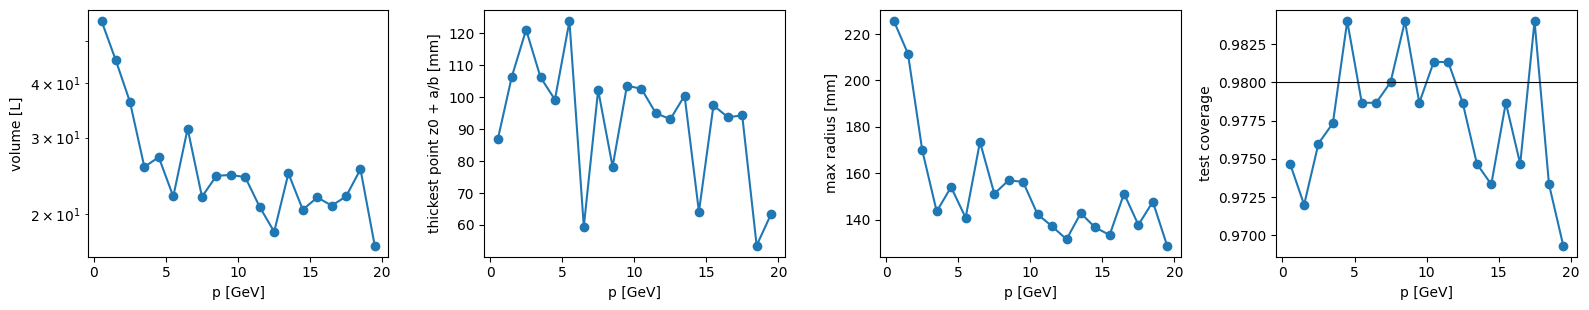

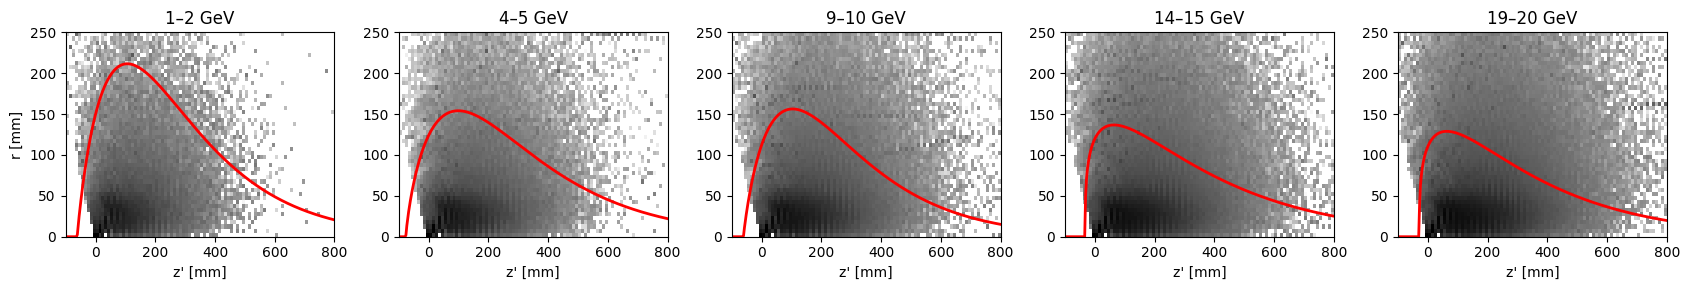

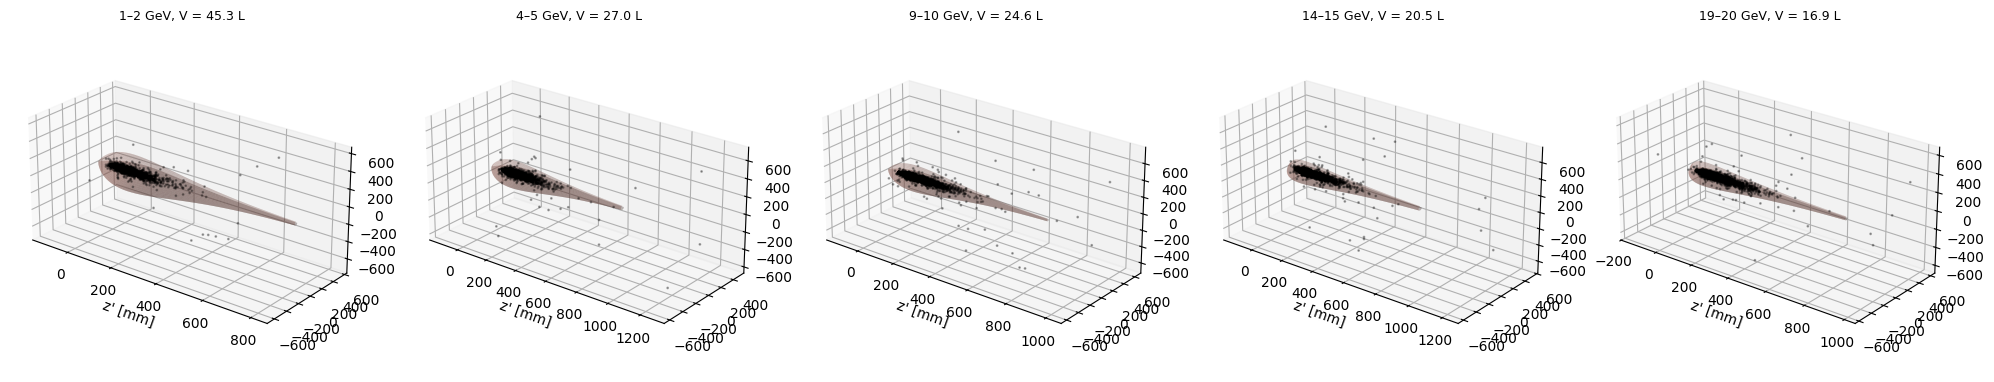

envelope saved for the summary notebook


In [8]:
p = tab.p_mean.values
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a_, (col, lab) in zip(ax, [("V_L", "volume [L]"), ("z_thick", "thickest point z0 + a/b [mm]"), ("r_max", "max radius [mm]"), ("cov_test", "test coverage")]):
    a_.plot(p, tab[col].values, "o-"); a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[3].axhline(F_EV, c="k", lw=0.8)
plt.tight_layout(); plt.show()

hits = data["train"].hits()
fig, axes = plt.subplots(1, len(SHOW_BINS), figsize=(3.4 * len(SHOW_BINS), 3))
zz = np.linspace(-100, 800, 300)
for ax_, b in zip(axes, SHOW_BINS):
    m = (hits.p >= b) & (hits.p < b + 1)
    ax_.hist2d(hits.z[m], hits.r[m], bins=[np.linspace(-100, 800, 91), np.linspace(0, 250, 51)], weights=hits.w[m],
               norm=matplotlib.colors.LogNorm(), cmap="Greys")
    if b in ENV:
        e = ENV[b]; u = np.clip(zz - e["z0"], 0, None)
        ax_.plot(zz, e["A"] * u ** e["a"] * np.exp(-e["b"] * u), "r-", lw=2)
    ax_.set_title(f"{b}–{b + 1} GeV"); ax_.set_xlabel("z' [mm]")
axes[0].set_ylabel("r [mm]"); plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(4 * len(SHOW_BINS), 3.8))
for j, b in enumerate([b for b in SHOW_BINS if b in ENV]):
    ax_ = fig.add_subplot(1, len(SHOW_BINS), j + 1, projection="3d")
    e = ENV[b]; u = np.clip(zz - e["z0"], 0, None)
    ax_.plot_surface(*revolve(zz, e["A"] * u ** e["a"] * np.exp(-e["b"] * u)), color="tab:brown", alpha=0.35, linewidth=0)
    m = np.where((hits.p >= b) & (hits.p < b + 1))[0]
    sel = np.random.default_rng(0).choice(m, min(2000, len(m)), p=hits.w.values[m] / hits.w.values[m].sum())
    ph = np.random.default_rng(1).uniform(0, 2 * np.pi, len(sel))
    ax_.scatter(hits.z.values[sel], hits.r.values[sel] * np.cos(ph), hits.r.values[sel] * np.sin(ph), s=1, c="k", alpha=0.3)
    ax_.set_title(f"{b}–{b + 1} GeV, V = {e['V_L']:.1f} L", fontsize=9); ax_.set_xlabel("z' [mm]")
    ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
plt.tight_layout(); plt.show()
torch.save({"bins": ENV, "smooth": {k: v.tolist() for k, v in SMOOTH.items()}, "f_E": F_E, "f_ev": F_EV},
           f"{OUT_DIR}/electron/envelope_export.pt")
print("envelope saved for the summary notebook")

### 2D map with $(z', r)$ axes, in the same form as the GFlash `shape_map` plot

The same view as for the GFlash results: $z'$ horizontal, $r$ mirrored ($\pm r$, mm), $\log_{10}$ density, 5-decade colour scale,
$p = 1, 5, 10, 18$ GeV.
- **Background:** mean energy density of the training data in the given 1 GeV bin, on the same $(z', r)$ grid as the model maps.
  This is the distribution of cell centres, not deconvolved, so it is coarser in $r$ than the GFlash "true shape".
- **White line:** the envelope fitted in the bin. **Cyan dashed:** the smoothed ($\ln p$ polynomial) envelope at the bin mean momentum.
- **Green dotted** (if a GFlash export exists): radius of the GFlash region containing 95% of the energy, $r_{95}(z')$. This is for the **average** shower,
  so it is expected to stay inside the envelope.

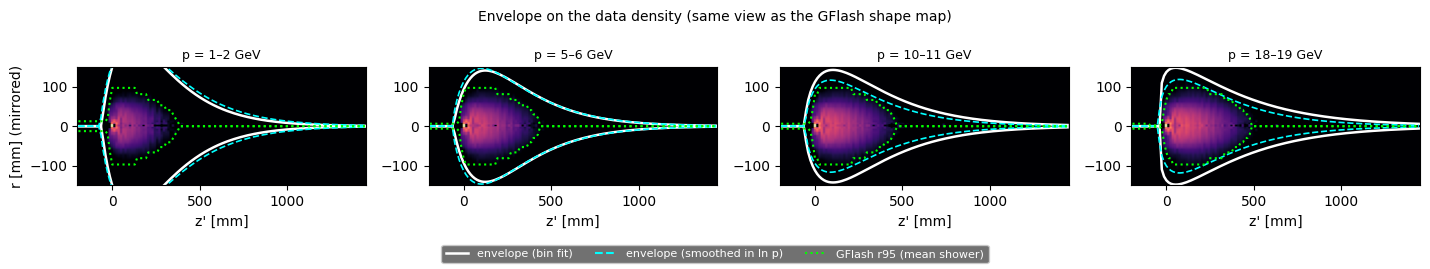

In [9]:
def envelope_r(z, e):
    u = np.clip(z - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def smooth_envelope(p):
    L = np.log(p)
    v = {k: np.polynomial.polynomial.polyval(L, c) for k, c in SMOOTH.items()}
    a, zenv = np.exp(v["ln a"]), np.exp(v["ln z_env"])
    return {"a": a, "b": a / zenv, "z0": v["z0"], "A": np.exp(v["ln A"])}


def envelope_map(sh, p_values=(1, 5, 10, 18), r_show=150, title=""):
    """Same layout as shape_map: data density in the p bin (log10, mirrored in r) + envelope outlines."""
    zc, rc = ZC.cpu().numpy(), RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    gf_path = f"{OUT_DIR}/electron/export_gflash.pt"
    gf = TableModel(torch.load(gf_path, weights_only=False)) if os.path.exists(gf_path) else None
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.6))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[Z_EDGES.cpu().numpy(), R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        if b in ENV:
            r = envelope_r(zc, ENV[b])
            ax.plot(zc, r, "w-", lw=1.8); ax.plot(zc, -r, "w-", lw=1.8)
            rs_ = envelope_r(zc, smooth_envelope(ENV[b]["p_mean"]))
            ax.plot(zc, rs_, c="cyan", ls="--", lw=1.2); ax.plot(zc, -rs_, c="cyan", ls="--", lw=1.2)
        if gf is not None:
            with torch.no_grad():
                P = gf(torch.log(torch.tensor([b + 0.5], device=DEVICE))).exp()[0].cpu().numpy()
            r95 = iso_radius(P, 0.95)
            ax.plot(zc, r95, c="lime", ls=":", lw=1.5); ax.plot(zc, -r95, c="lime", ls=":", lw=1.5)
        ax.set_ylim(-r_show, r_show)
        ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9)
        ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], c="w", lw=1.8, label="envelope (bin fit)"),
               plt.Line2D([], [], c="cyan", ls="--", label="envelope (smoothed in ln p)")]
    if gf is not None:
        handles.append(plt.Line2D([], [], c="lime", ls=":", label="GFlash r95 (mean shower)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()


envelope_map(data["train"], title="Envelope on the data density (same view as the GFlash shape map)")